Import the modules that will be used.

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

Response to Exercise 11.1

1) Dot product between 2 vectors: O($n$), linear complexity. Since the vectors have length $n$, the multiplication operator is performed n times.
2) Matrix-vector product: O($n^2$), quadratic complexity. The multiplication operator is carried out $n*n$ = $n^2$ times, and the addition operator is performed $n*(n-1)$ = $n^2-n$ times. Together, they add up to $2n^2$-$n$.
3) Matrix-matrix product: O($n^3$), cubic complexity. The multiplication operator is carried out $n^3$ times, and the addition operator is performed $n^2*(n-1)$ = $n^3-n^2$ times. Together, they add up to $2n^3$-$n^2$.

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [3]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

In [4]:
N = 2**np.arange(2, 10)
times = []

for n in N:
    t = %timeit -q -n2 -r2 -o factorial(int(n))
    times.append(t.best)

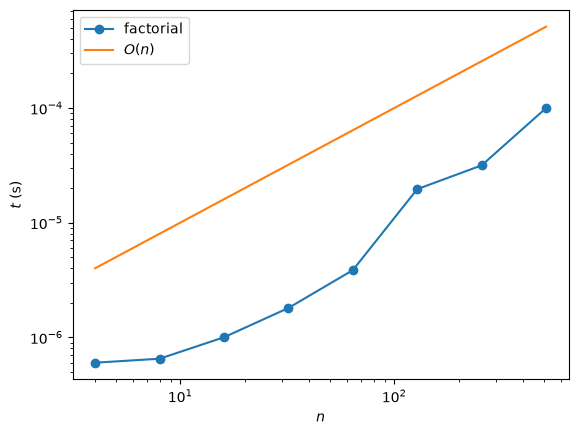

In [5]:
plt.loglog(N, times, marker='o', label='factorial')
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')

# Show a reference line of O(n)
plt.loglog(N, 1e-6*N, label='$O(n)$')

# Add legend
plt.legend(loc=0)

plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [3]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [4]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [5]:
N = 2**np.arange(2, 12)
times = []

for n in N:
    A = np.random.rand(n, n)
    t = %timeit -q -n4 -r1 -o np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

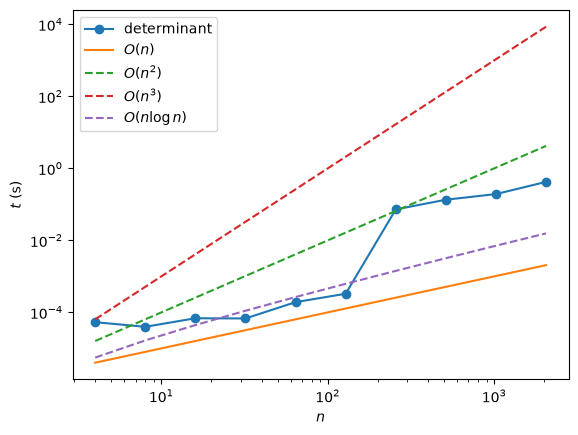

In [8]:
# Plot time taken for determinant calculation
plt.loglog(N, times, marker='o', label='determinant')

# Show reference lines
plt.loglog(N, 1e-6*N, label='$O(n)$')
plt.loglog(N, 1e-6*N**2, '--', label=r'$O(n^2$)')
plt.loglog(N, 1e-6*N**3, '--', label=r'$O(n^3$)')
plt.loglog(N, 1e-6*N*np.log(N), '--', label=r'$O(n\log n)$')

# Add legend
plt.legend(loc=0)

plt.xlabel('$n$')
plt.ylabel('$t$ (s)')

plt.show()